<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Minería de Datos · Proyecto Final</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Análisis Exploratorio del Spanish Fake News Corpus</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Miguel A. Garcia, Nadia Ramos, Ángel J. Zamora</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

Proyecto basado en *FakeDeS: Fake News Detection in Spanish Shared Task at IberLEF 2021*, organizada en colaboración con MexLef.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metodología CRISM-DM: Comprensión de los datos</span></div>

Acorde a la página oficial de FakeDeS $^{[6]}$, el corpus consiste en novecientas setenta y una (971) noticias recopiladas principalmente de recursos digitales mexicanos, y cubre nueve (9) temas en particular: Ciencia, deportes, economía, educación, entretenimiento, política, salud, seguridad y sociedad recolectadas desde enero hasta julio de 2018 considerando una única variable objetivo: *‘true’* o *‘fake’*. Consta de las siguientes variables:

| Variable | Descripción |
| :--- | :--- |
| `Category` | Indica si la noticia es verdadera (*true*) o falsa (*fake*). |
| `Topic` | Tema del registro entre los mencionados anteriormente. |
| `Source` | Nombre de la página de origen del registro. |
| `Headline` | Título de la noticia en el registro. |
| `Text` | Texto completo de la noticia. |
| `Link` | Enlace al contenido publicado original. |

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Preparación de entorno</span></div>

In [ ]:
# Manejo de datos
import os
import re
from collections import Counter
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibilidad
random_state = 42

# Ubicación de los datos
ruta_datos = 'data'
archivos = {'train': 'train.xlsx', 'development': 'development.xlsx', 'test': 'test.xlsx'}

# Colores por clase y por partición
colores_clase = {'True': 'C0', 'Fake': 'red'}
colores_part = {'train': 'C0', 'development': 'orange', 'test': 'red'}

# Palabras vacías del español para el análisis de vocabulario
import stopwordsiso as sw
stopwords = sw.stopwords("es")

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conjunto de datos</span></div>

El repositorio contiene tres archivos de Excel que corresponden a dos versiones del corpus:

| Archivo | Versión | Periodo de recolección | Uso original |
|:--|:--|:--|:--|
| `train.xlsx` | 1.0 | Enero a julio de 2018 | Entrenamiento (MEX-A3T 2020) |
| `development.xlsx` | 1.0 | Enero a julio de 2018 | Prueba de MEX-A3T 2020; desarrollo en FakeDeS 2021 |
| `test.xlsx` | 2.0 | Noviembre de 2020 a marzo de 2021 | Prueba (FakeDeS 2021) |

Según el README, la versión 1.0 se dividió en 70% para entrenamiento y 30% para prueba de forma estratificada por tema, y la versión 2.0 se armó por pares de noticias falsa y verdadera sobre el mismo hecho. Cada registro tiene las columnas:

* **Id:** identificador de la instancia.
* **Category:** clase de la noticia (verdadera o falsa). Es la variable objetivo.
* **Topic:** tema de la noticia.
* **Source:** nombre del medio o sitio de origen.
* **Headline:** titular.
* **Text:** texto completo de la noticia.
* **Link:** URL de la fuente.

In [2]:
def cargar_archivo(archivo):
    '''
    Función que lee un archivo del corpus desde la carpeta local o desde el repositorio original

    inputs:
    --------
        archivo (str): Nombre del archivo .xlsx

    outputs:
    --------
        pandas.DataFrame: Contenido del archivo sin modificar
    '''
    ruta = os.path.join(ruta_datos, archivo)
    return pd.read_excel(ruta if os.path.exists(ruta) else url_repo + archivo)

crudos = {particion: cargar_archivo(archivo) for particion, archivo in archivos.items()}

display(crudos['train'].head())
for particion, df in crudos.items():
    print(f' Tamaño de {particion}: {df.shape}')

,Id,Category,Topic,Source,Headline,Text,Link
0,1,Fake,Education,El Ruinaversal,"RAE INCLUIRÁ LA PALABRA ""LADY"" EN EL DICCIONAR...","RAE INCLUIRÁ LA PALABRA ""LADY"" EN EL DICCIONAR...",http://www.elruinaversal.com/2017/06/10/rae-in...
1,2,Fake,Education,Hay noticia,"La palabra ""haiga"", aceptada por la RAE","La palabra ""haiga"", aceptada por la RAE La Rea...",https://haynoticia.es/la-palabra-haiga-aceptad...
2,3,Fake,Education,El Ruinaversal,YORDI ROSADO ESCRIBIRÁ Y DISEÑARÁ LOS NUEVOS L...,YORDI ROSADO ESCRIBIRÁ Y DISEÑARÁ LOS NUEVOS L...,http://www.elruinaversal.com/2018/05/06/yordi-...
3,4,True,Education,EL UNIVERSAL,UNAM capacitará a maestros para aprobar prueba...,UNAM capacitará a maestros para aprobar prueba...,http://www.eluniversal.com.mx/articulo/nacion/...
4,5,Fake,Education,Lamula,pretenden aprobar libros escolares con conteni...,Alerta: pretenden aprobar libros escolares con...,https://redaccion.lamula.pe/2018/06/19/memoria...


 Tamaño de train: (676, 7)
 Tamaño de development: (295, 7)
 Tamaño de test: (572, 7)


In [3]:
# Columnas y tipos de cada archivo
display(pd.DataFrame({p: df.dtypes.astype(str).values for p, df in crudos.items()},
                     index = [f'columna {i + 1}' for i in range(7)]))
print(f'Columnas de train: {list(crudos["train"].columns)}')
print(f'Columnas de test: {list(crudos["test"].columns)}')
print(f'\nValores de Category en train: {list(crudos["train"]["Category"].unique())}')
print(f'Valores de CATEGORY en test: {list(crudos["test"]["CATEGORY"].unique())}')
print(f'\nTemas en train: {sorted(crudos["train"]["Topic"].unique())}')
print(f'Temas en test: {sorted(crudos["test"]["TOPICS"].unique())}')

,train,development,test
columna 1,int64,int64,int64
columna 2,str,str,bool
columna 3,str,str,str
columna 4,str,str,str
columna 5,str,str,str
columna 6,str,str,str
columna 7,str,str,str


Columnas de train: ['Id', 'Category', 'Topic', 'Source', 'Headline', 'Text', 'Link']
Columnas de test: ['ID', 'CATEGORY', 'TOPICS', 'SOURCE', 'HEADLINE', 'TEXT', 'LINK']

Valores de Category en train: ['Fake', 'True']
Valores de CATEGORY en test: [np.True_, np.False_]

Temas en train: ['Economy', 'Education', 'Entertainment', 'Health', 'Politics', 'Science', 'Security', 'Society', 'Sport']
Temas en test: ['Ambiental', 'Ciencia', 'Covid-19', 'Deporte', 'Internacional', 'Política', 'Sociedad']


## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Homogeneización</span></div>

Los archivos de la versión 1.0 y el de la 2.0 no comparten formato: en `test.xlsx` las columnas están en mayúsculas (y el tema se llama `TOPICS`), la clase es booleana en lugar de `True`/`Fake`, y los temas están en español. Para poder compararlos se renombran las columnas, se convierte la clase booleana a `True`/`Fake` y se traducen los temas al inglés con los nombres que usa el README. También se agrega la columna `version`.

In [4]:
temas_es = {'Covid-19': 'COVID-19', 'Sociedad': 'Society', 'Política': 'Politics', 'Internacional': 'International',
            'Ciencia': 'Science', 'Ambiental': 'Environment', 'Deporte': 'Sport'}

test = crudos['test'].copy()
test.columns = crudos['train'].columns
test['Category'] = test['Category'].map({True: 'True', False: 'Fake'})
test['Topic'] = test['Topic'].map(temas_es)

corpus = pd.concat([crudos['train'].assign(particion = 'train'),
                    crudos['development'].assign(particion = 'development'),
                    test.assign(particion = 'test')], ignore_index = True)
corpus['version'] = np.where(corpus['particion'] == 'test', '2.0', '1.0')
corpus = corpus.astype({c: 'object' for c in ['Category', 'Topic', 'Source', 'Headline', 'Text', 'Link']})

particiones = list(archivos)
print(f'Tamaño del corpus unificado: {corpus.shape}')
display(corpus.groupby('particion', sort = False)['Category'].value_counts().unstack())

Tamaño del corpus unificado: (1543, 9)


Category,Fake,True
particion,,
train,338,338
development,142,153
test,286,286


## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Calidad de los datos</span></div>

In [5]:
# Verificación de valores nulos
print('\t Cantidad de registros con valores nulos por partición:')
corpus.drop(columns = ['particion', 'version']).isnull().groupby(corpus['particion'], sort = False).sum()

	 Cantidad de registros con valores nulos por partición:


,Id,Category,Topic,Source,Headline,Text,Link
particion,,,,,,,
train,0,0,0,0,0,0,0
development,0,0,0,0,0,0,0
test,0,0,0,7,72,0,3


In [6]:
# ¿A qué clase pertenecen los registros de test sin titular o sin fuente?
nulos_test = corpus[corpus['particion'] == 'test']
display(pd.DataFrame({'sin Headline': nulos_test['Headline'].isnull().groupby(nulos_test['Category']).sum(),
                      'sin Source': nulos_test['Source'].isnull().groupby(nulos_test['Category']).sum(),
                      'sin Link': nulos_test['Link'].isnull().groupby(nulos_test['Category']).sum()}))
print('Fuentes de las noticias falsas sin titular:')
print(nulos_test.loc[nulos_test['Headline'].isnull(), 'Source'].value_counts().head(5))

,sin Headline,sin Source,sin Link
Category,,,
Fake,72,5,3
True,0,2,0


Fuentes de las noticias falsas sin titular:
Source
AFPFactual        58
Agencia EFE        7
Colombia Check     1
Facebook           1
Maldita            1
Name: count, dtype: int64


Solo `test.xlsx` tiene valores nulos, y **los 72 registros sin titular son noticias falsas**, la mayoría publicaciones de redes sociales verificadas por AFP Factual (el README aclara que algunas fuentes omiten el titular). Esto significa que la ausencia del titular delata la clase: un modelo que reciba un titular vacío podría aprender que eso indica una noticia falsa. En la preparación conviene rellenar el titular vacío con una cadena neutra y no usar su ausencia como variable.

In [7]:
# Duplicados y fuga entre particiones
train, dev = corpus[corpus['particion'] == 'train'], corpus[corpus['particion'] == 'development']
for p in particiones:
    df = corpus[corpus['particion'] == p]
    print(f'{p}: IDs duplicados = {df["Id"].duplicated().sum()}, textos duplicados = {df["Text"].duplicated().sum()}, '
          f'links duplicados = {df["Link"].dropna().duplicated().sum()}')

print(f'\nTextos de development presentes en train: {dev["Text"].isin(train["Text"]).sum()}')
print(f'Textos de test presentes en la versión 1.0: {test["Text"].isin(corpus.loc[corpus["version"] == "1.0", "Text"]).sum()}')
print(f'IDs de development que también existen en train: {dev["Id"].isin(train["Id"]).sum()} de {len(dev)}')

train: IDs duplicados = 0, textos duplicados = 0, links duplicados = 0
development: IDs duplicados = 0, textos duplicados = 1, links duplicados = 1
test: IDs duplicados = 0, textos duplicados = 0, links duplicados = 0

Textos de development presentes en train: 4


Textos de test presentes en la versión 1.0: 0


IDs de development que también existen en train: 295 de 295


In [8]:
# Variantes de escritura en los nombres de las fuentes
for p in particiones:
    fuentes = corpus.loc[corpus['particion'] == p, 'Source'].dropna()
    print(f'{p}: {fuentes.nunique()} fuentes distintas, {fuentes.str.strip().str.lower().nunique()} al normalizar mayúsculas y espacios')

normalizada = corpus['Source'].str.strip().str.lower()
variantes = corpus.groupby(normalizada)['Source'].unique()
print('\nEjemplos de una misma fuente escrita de varias formas:')
print(variantes[variantes.str.len() > 1].head(8).to_string())

train: 134 fuentes distintas, 122 al normalizar mayúsculas y espacios
development: 82 fuentes distintas, 72 al normalizar mayúsculas y espacios
test: 205 fuentes distintas, 199 al normalizar mayúsculas y espacios



Ejemplos de una misma fuente escrita de varias formas:


Source
abc                                                 [ABC, abc]
alerta digital                [Alerta digital, Alerta Digital]
animal político             [Animal Político, Animal político]
argumento político    [Argumento Político, ARGUMENTO POLÍTICO]
aristegui noticias    [Aristegui noticias, Aristegui Noticias]
as                                                    [as, AS]
cnn español                         [CNN español, CNN Español]
el comercio                         [El Comercio, El comercio]


In [9]:
# Marcas de anonimización y relación entre titular y texto
corpus['marcas'] = corpus['Text'].str.findall(r'\*[A-Z]+\*')
display(corpus.explode('marcas').groupby('particion', sort = False)['marcas'].value_counts().unstack(fill_value = 0))

con_titular = corpus.dropna(subset = ['Headline'])
inicia = con_titular.apply(lambda r: r['Text'].strip().lower().startswith(r['Headline'].strip().lower()[:30]), axis = 1)
print('Proporción de textos que empiezan con su propio titular:')
print(inicia.groupby(con_titular['particion'], sort = False).mean().round(3))
corpus = corpus.drop(columns = ['marcas'])

marcas,*NUMBER*,*PHONE*,*URL*
particion,,,
train,3384,10,11
development,1692,2,5


Proporción de textos que empiezan con su propio titular:
particion
train          0.969
development    0.986
test           0.010
dtype: float64


En la versión 1.0 los números, URLs y teléfonos se reemplazaron por las marcas `*NUMBER*`, `*URL*` y `*PHONE*`, y casi todos los textos empiezan repitiendo el titular. En la versión 2.0 no ocurre ninguna de las dos cosas. Si se entrena con la 1.0 y se evalúa con la 2.0, hay que aplicar la misma normalización a ambas (reemplazar números en `test` o quitar las marcas en `train`) y decidir de forma explícita cómo combinar titular y texto.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Distribución de clases</span></div>

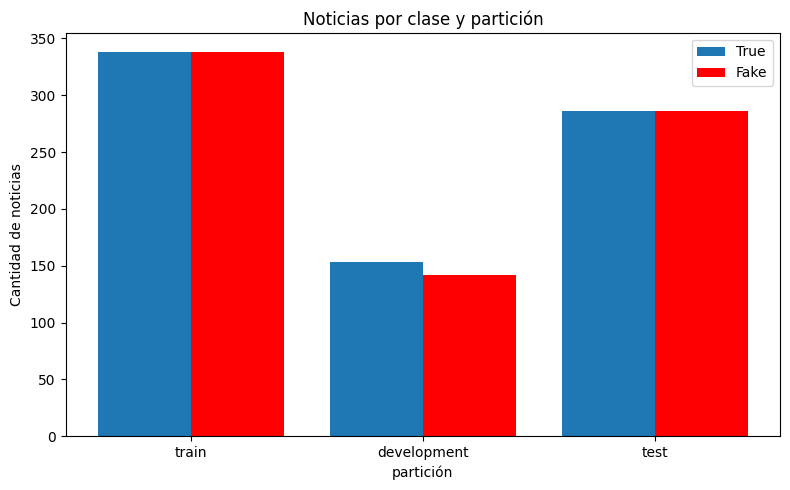

Category,Fake,True,% Fake
particion,,,
train,338,338,50.0
development,142,153,48.1
test,286,286,50.0


In [10]:
clases = pd.crosstab(corpus['particion'], corpus['Category']).loc[particiones]
x = np.arange(len(clases))

plt.figure(figsize = (8, 5))
plt.bar(x - 0.2, clases['True'], width = 0.4, color = colores_clase['True'], label = 'True')
plt.bar(x + 0.2, clases['Fake'], width = 0.4, color = colores_clase['Fake'], label = 'Fake')
plt.xticks(x, clases.index)
plt.xlabel('partición')
plt.ylabel('Cantidad de noticias')
plt.title('Noticias por clase y partición')
plt.legend()
plt.tight_layout()
plt.show()

clases['% Fake'] = (100 * clases['Fake'] / clases[['Fake', 'True']].sum(axis = 1)).round(1)
display(clases)

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Temas</span></div>

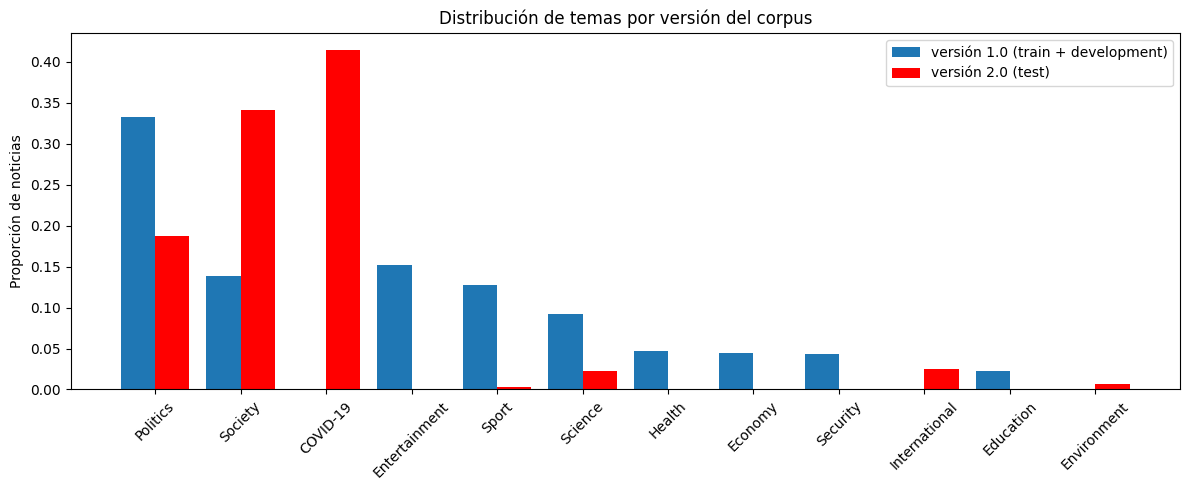

Temas exclusivos de la versión 1.0: ['Economy', 'Education', 'Entertainment', 'Health', 'Security']
Temas exclusivos de la versión 2.0: ['COVID-19', 'Environment', 'International']


In [11]:
# Distribución de temas por versión
temas = pd.crosstab(corpus['Topic'], corpus['version'], normalize = 'columns')
temas = temas.loc[temas.sum(axis = 1).sort_values(ascending = False).index]
x = np.arange(len(temas))

plt.figure(figsize = (12, 5))
plt.bar(x - 0.2, temas['1.0'], width = 0.4, label = 'versión 1.0 (train + development)')
plt.bar(x + 0.2, temas['2.0'], width = 0.4, color = 'red', label = 'versión 2.0 (test)')
plt.xticks(x, temas.index, rotation = 45)
plt.ylabel('Proporción de noticias')
plt.title('Distribución de temas por versión del corpus')
plt.legend()
plt.tight_layout()
plt.show()

print('Temas exclusivos de la versión 1.0:', sorted(set(corpus.loc[corpus['version'] == '1.0', 'Topic']) - set(test['Topic'])))
print('Temas exclusivos de la versión 2.0:', sorted(set(test['Topic']) - set(corpus.loc[corpus['version'] == '1.0', 'Topic'])))

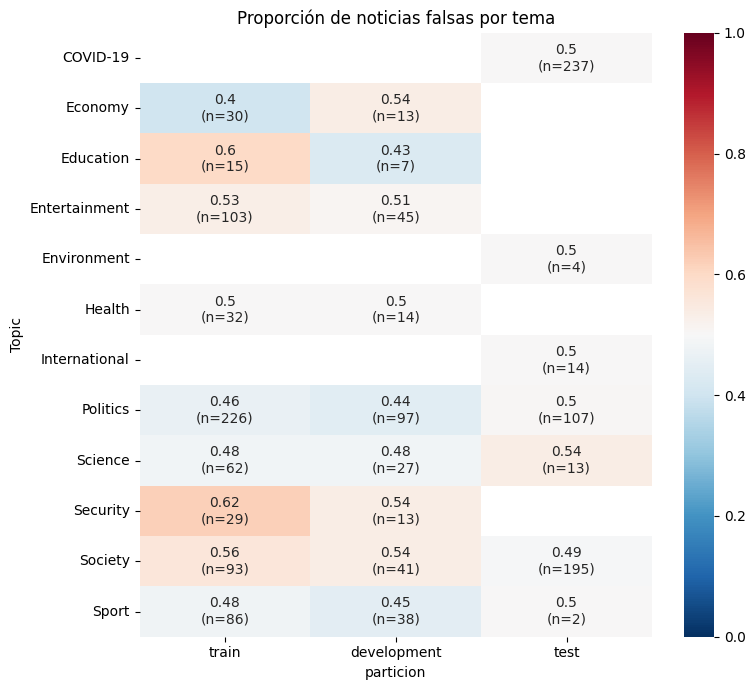

In [12]:
# Proporción de noticias falsas por tema y partición
fake_tema = corpus.assign(fake = corpus['Category'] == 'Fake').pivot_table(index = 'Topic', columns = 'particion',
                                                                          values = 'fake', aggfunc = 'mean')[particiones]
n_tema = corpus.pivot_table(index = 'Topic', columns = 'particion', values = 'Id', aggfunc = 'count')[particiones]
etiquetas_celda = fake_tema.round(2).astype(str) + '\n(n=' + n_tema.fillna(0).astype(int).astype(str) + ')'

plt.figure(figsize = (8, 7))
sns.heatmap(fake_tema, annot = etiquetas_celda.where(n_tema.notnull(), ''), fmt = '', cmap = 'RdBu_r', vmin = 0, vmax = 1)
plt.title('Proporción de noticias falsas por tema')
plt.tight_layout()
plt.show()

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Fuentes</span></div>

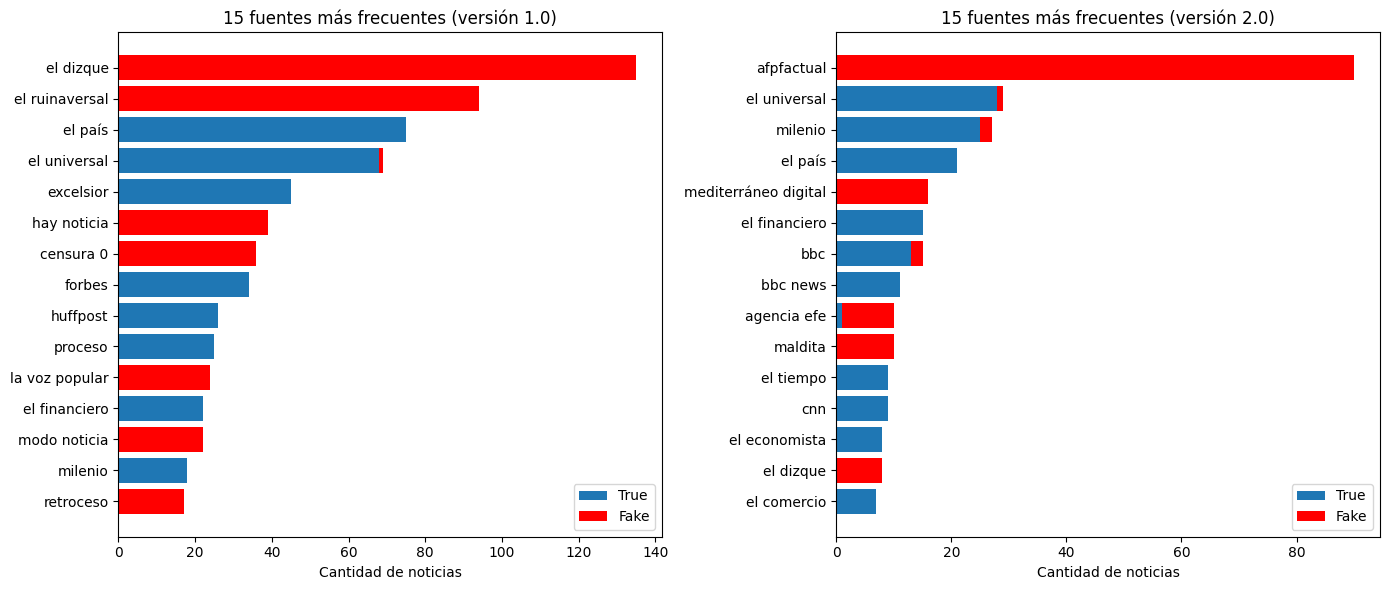

In [13]:
corpus['fuente'] = corpus['Source'].str.strip().str.lower()
corpus['dominio'] = corpus['Link'].str.extract(r'https?://(?:www\.)?([^/]+)', expand = False)

# Fuentes más frecuentes por versión, separadas por clase
plt.figure(figsize = (14, 6))
for i, version in enumerate(['1.0', '2.0']):
    df = corpus[corpus['version'] == version]
    top = pd.crosstab(df['fuente'], df['Category'])
    top = top.loc[top.sum(axis = 1).sort_values().index[-15:]]
    plt.subplot(1, 2, i + 1)
    plt.barh(top.index, top['True'], color = colores_clase['True'], label = 'True')
    plt.barh(top.index, top['Fake'], left = top['True'], color = colores_clase['Fake'], label = 'Fake')
    plt.xlabel('Cantidad de noticias')
    plt.title(f'15 fuentes más frecuentes (versión {version})')
    plt.legend()
plt.tight_layout()
plt.show()

In [14]:
def pureza(df, columna):
    '''
    Función que mide qué tanto determina una columna la clase de la noticia

    inputs:
    --------
        df (pandas.DataFrame): Registros a evaluar
        columna (str): Columna categórica ('fuente' o 'dominio')

    outputs:
    --------
        pandas.Series: Cantidad de valores distintos y proporción de noticias cuyo valor publica una sola clase
    '''
    df = df.dropna(subset = [columna])
    una_clase = df.groupby(columna)['Category'].transform('nunique') == 1
    return pd.Series({'valores distintos': df[columna].nunique(), '% noticias en valores de una sola clase': round(100 * una_clase.mean(), 1)})

display(pd.DataFrame({(p, c): pureza(corpus[corpus['particion'] == p], c) for p in particiones for c in ['fuente', 'dominio']}))

train         development          \
                                        fuente dominio      fuente dominio   
valores distintos                        122.0   111.0        72.0    72.0   
% noticias en valores de una sola clase   93.0    91.6       100.0    98.3   

                                          test          
                                        fuente dominio  
valores distintos                        199.0   213.0  
% noticias en valores de una sola clase   81.1    77.6

In [15]:
# ¿Las fuentes de development y test ya aparecen en train?
fuentes_train = set(train['Source'].str.strip().str.lower())
for p in ['development', 'test']:
    df = corpus[corpus['particion'] == p]
    print(f'Noticias de {p} cuya fuente aparece en train: {round(100 * df["fuente"].isin(fuentes_train).mean(), 1)}%')

Noticias de development cuya fuente aparece en train: 90.5%
Noticias de test cuya fuente aparece en train: 34.3%


La fuente casi determina la clase: en la versión 1.0, más del 90% de las noticias proviene de un medio que solo publica una de las dos clases. Las falsas vienen sobre todo de sitios satíricos o de rumores (*El Dizque*, *El Ruinaversal*, *Hay noticia*, *Censura 0*) y las verdaderas de periódicos establecidos (*El País*, *Excelsior*, *El Universal*). En la versión 2.0 el caso más claro es *AFPFactual*: sus 90 registros son falsos, porque la fuente anotada es el verificador que desmintió la publicación (son las 90 publicaciones de redes sociales que menciona el README), y lo mismo pasa con *Maldita* y casi todos los de *Agencia EFE*. Por eso `Source` y `Link` **no deben usarse como variables de entrada**, y aun usando solo el texto, un modelo puede aprender el estilo de cada medio en lugar de la veracidad. Como la versión 2.0 usa fuentes casi totalmente distintas, evaluar con ella mide mejor la capacidad de generalizar.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Longitud de los textos</span></div>

La longitud se mide en palabras (separadas por espacios), lo cual es adecuado para el español. Se omiten los valores atípicos en los diagramas de caja para que la escala sea legible.

,count,mean,std,min,25%,50%,75%,max
particion,,,,,,,,
train,676.0,377.9,255.9,20.0,223.0,314.5,458.2,2081.0
development,295.0,417.2,337.0,51.0,229.0,321.0,481.5,2566.0
test,572.0,521.3,438.0,47.0,250.0,398.5,653.0,4006.0


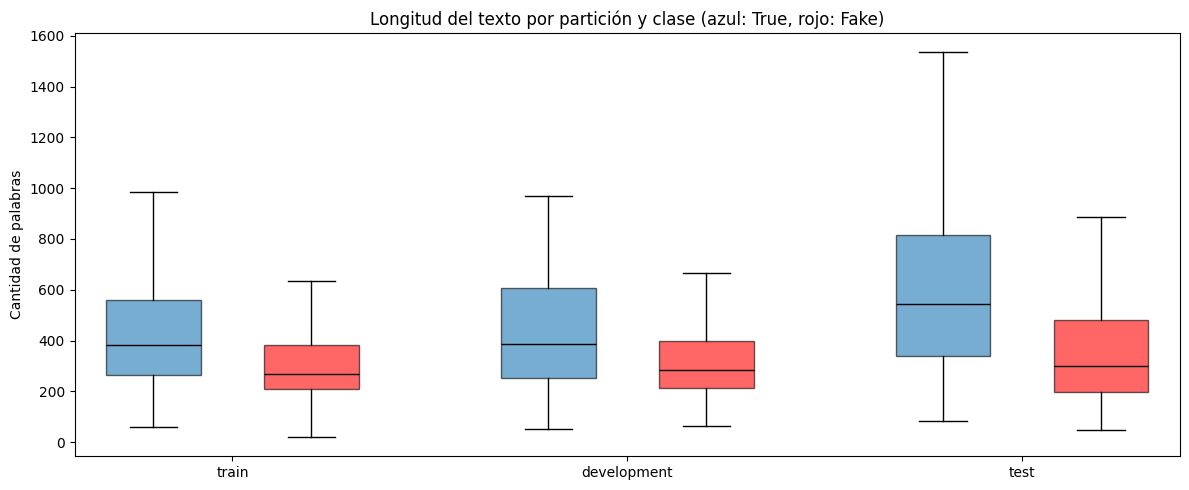

In [16]:
corpus['n_palabras'] = corpus['Text'].str.split().str.len()
corpus['n_palabras_titular'] = corpus['Headline'].str.split().str.len()
display(corpus.groupby('particion', sort = False)['n_palabras'].describe().round(1))

plt.figure(figsize = (12, 5))
pos = 0
for p in particiones:
    for clase in ['True', 'Fake']:
        datos = corpus.loc[(corpus['particion'] == p) & (corpus['Category'] == clase), 'n_palabras']
        caja = plt.boxplot(datos, positions = [pos], widths = 0.6, showfliers = False, patch_artist = True,
                           medianprops = {'color': 'black'})
        caja['boxes'][0].set_facecolor(colores_clase[clase])
        caja['boxes'][0].set_alpha(0.6)
        pos += 1
    pos += 0.5
plt.xticks([0.5, 3, 5.5], particiones)
plt.ylabel('Cantidad de palabras')
plt.title('Longitud del texto por partición y clase (azul: True, rojo: Fake)')
plt.tight_layout()
plt.show()

In [17]:
# Mediana de palabras del texto y del titular por partición y clase
display(corpus.groupby(['particion', 'Category'], sort = False)[['n_palabras', 'n_palabras_titular']].median().unstack())

n_palabras        n_palabras_titular      
Category          Fake   True               Fake  True
particion                                             
train            269.0  382.0               12.0  10.0
development      283.5  385.0               12.0  10.0
test             301.0  545.0               13.0  12.0

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Rasgos de estilo</span></div>

Se calculan algunos rasgos superficiales que suelen asociarse con el sensacionalismo: la proporción de letras mayúsculas y la frecuencia de signos de exclamación, de interrogación y de comillas por cada mil caracteres. En la versión 1.0 la proporción de mayúsculas está inflada porque el texto empieza con el titular escrito en mayúsculas, así que se calcula sin la primera línea.

In [18]:
cuerpo = corpus['Text'].where(corpus['version'] == '2.0', corpus['Text'].str.split('\n', n = 1).str[-1])
n_car = cuerpo.str.len()

corpus['% mayúsculas'] = 100 * cuerpo.str.count(r'[A-ZÁÉÍÓÚÑ]') / cuerpo.str.count(r'[A-Za-zÁÉÍÓÚÑáéíóúñ]')
corpus['exclamaciones'] = 1000 * cuerpo.str.count(r'[!¡]') / n_car
corpus['interrogaciones'] = 1000 * cuerpo.str.count(r'[?¿]') / n_car
corpus['comillas'] = 1000 * cuerpo.str.count(r'["“”«»]') / n_car
rasgos = ['% mayúsculas', 'exclamaciones', 'interrogaciones', 'comillas']

display(corpus.groupby(['version', 'Category'])[rasgos].mean().round(2))

% mayúsculas  exclamaciones  interrogaciones  comillas
version Category                                                        
1.0     Fake              3.92           0.21             0.35      3.44
        True              5.36           0.09             0.15      3.14
2.0     Fake              4.94           0.51             0.86      3.00
        True              2.83           0.05             0.27      3.22

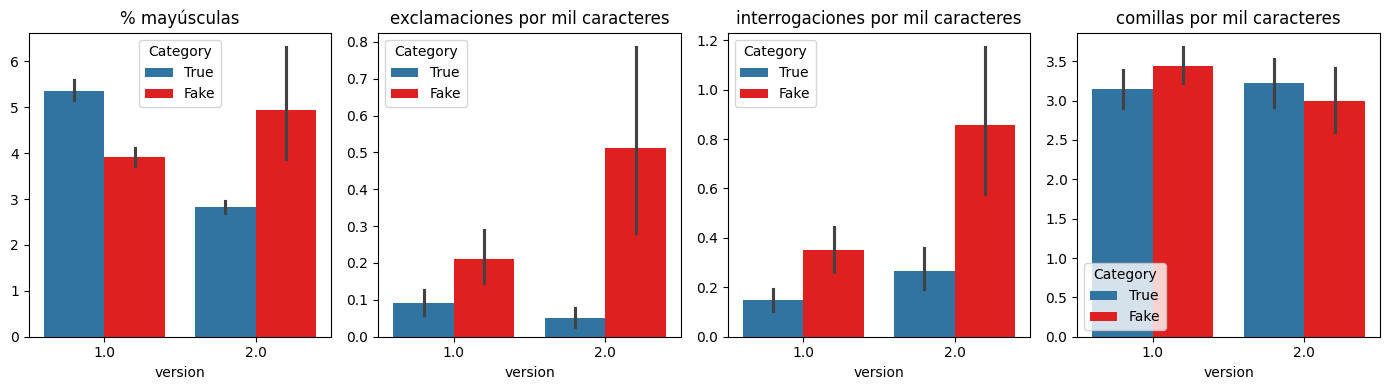

In [19]:
plt.figure(figsize = (14, 4))
for i, rasgo in enumerate(rasgos):
    plt.subplot(1, 4, i + 1)
    sns.barplot(data = corpus, x = 'version', y = rasgo, hue = 'Category', palette = colores_clase,
                hue_order = ['True', 'Fake'], errorbar = ('ci', 95), seed = random_state)
    plt.title(rasgo if i == 0 else f'{rasgo} por mil caracteres')
    plt.ylabel('')
plt.tight_layout()
plt.show()

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Vocabulario</span></div>

Se tokeniza en minúsculas conservando solo palabras alfabéticas, y se eliminan las marcas de anonimización y las palabras vacías. Para encontrar las palabras que distinguen a cada clase se usa el logaritmo de la razón entre su frecuencia relativa en noticias falsas y en verdaderas, con suavizado de Laplace, contando en cuántas noticias de cada clase aparece cada palabra (y no cuántas veces se repite) para que los nombres propios de un solo artículo no dominen, y considerando solo palabras presentes en al menos 10 noticias.

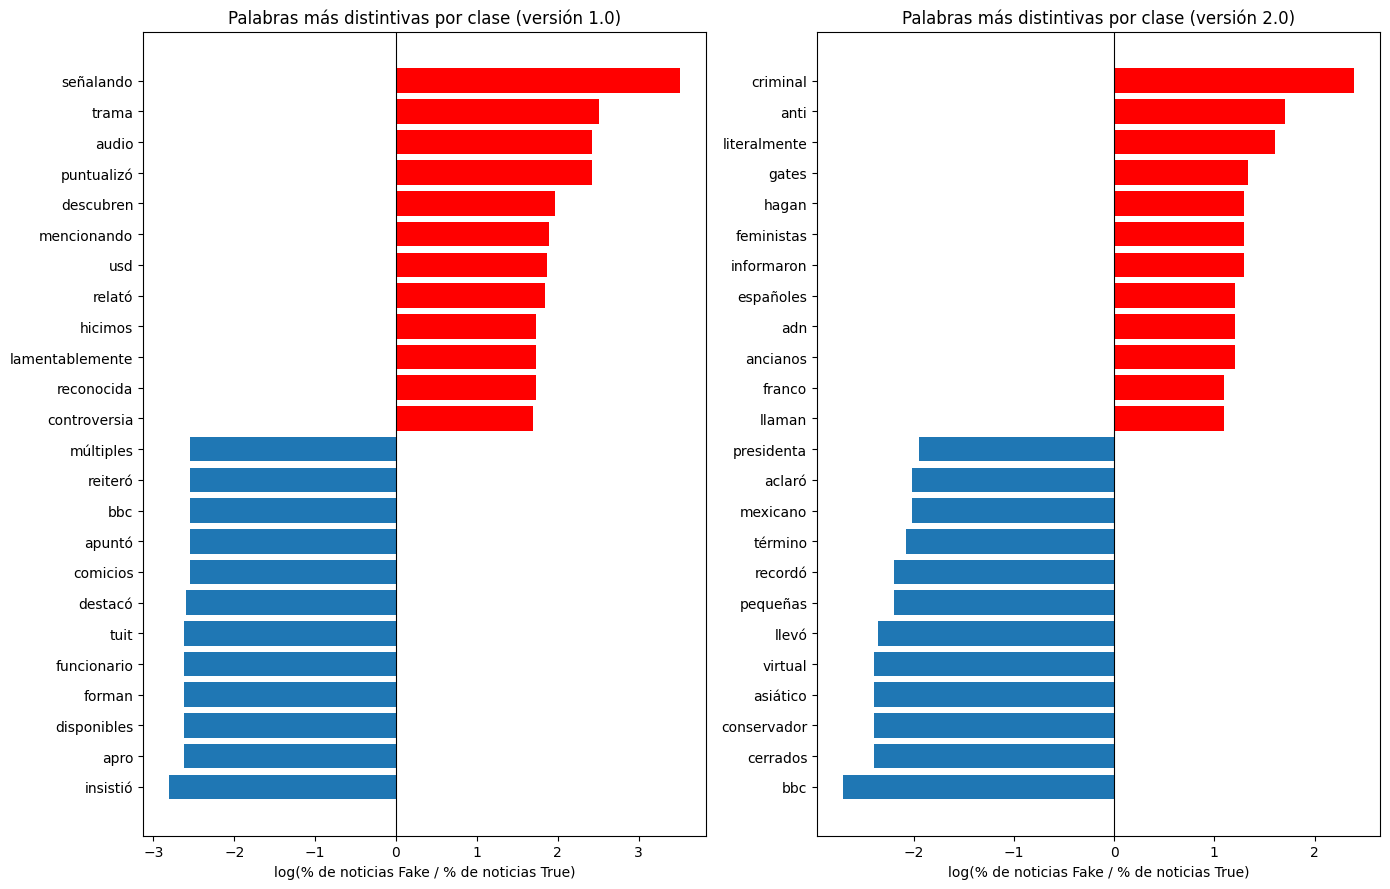

In [20]:
def tokenizar(texto):
    '''
    Función que convierte un texto en una lista de palabras útiles

    inputs:
    --------
        texto (str): Texto de la noticia

    outputs:
    --------
        list: Palabras en minúsculas, sin marcas de anonimización ni palabras vacías
    '''
    texto = re.sub(r'\*[A-Z]+\*', ' ', texto).lower()
    return [t for t in re.findall(r'[a-záéíóúñü]+', texto) if t not in stopwords and len(t) > 2]

corpus['tokens'] = corpus['Text'].apply(tokenizar)

def log_razon(df, minimo = 10):
    '''
    Función que calcula el logaritmo de la razón Fake / True de la frecuencia documental relativa de cada palabra

    inputs:
    --------
        df (pandas.DataFrame): Registros con la columna 'tokens'
        minimo (int): Cantidad mínima de noticias en las que debe aparecer una palabra

    outputs:
    --------
        pandas.Series: Log-razón por palabra (positiva: más propia de Fake)
    '''
    cuentas = {c: Counter(t for ts in df.loc[df['Category'] == c, 'tokens'] for t in set(ts)) for c in ['Fake', 'True']}
    tabla = pd.DataFrame(cuentas).fillna(0)
    tabla = tabla[tabla.sum(axis = 1) >= minimo]
    n_docs = df['Category'].value_counts()
    frec = (tabla + 1) / (n_docs[tabla.columns] + 2)
    return np.log(frec['Fake'] / frec['True']).sort_values()

plt.figure(figsize = (14, 9))
for i, version in enumerate(['1.0', '2.0']):
    lr = log_razon(corpus[corpus['version'] == version])
    extremos = pd.concat([lr.head(12), lr.tail(12)])
    plt.subplot(1, 2, i + 1)
    plt.barh(extremos.index, extremos.values, color = np.where(extremos > 0, colores_clase['Fake'], colores_clase['True']))
    plt.axvline(0, color = 'black', linewidth = 0.8)
    plt.xlabel('log(% de noticias Fake / % de noticias True)')
    plt.title(f'Palabras más distintivas por clase (versión {version})')
plt.tight_layout()
plt.show()

In [21]:
# Cobertura del vocabulario de test por el de la versión 1.0
vocab_v1 = Counter(t for ts in corpus.loc[corpus['version'] == '1.0', 'tokens'] for t in ts)
tokens_test = [t for ts in corpus.loc[corpus['version'] == '2.0', 'tokens'] for t in ts]
vocab_test = set(tokens_test)

print(f'Tamaño del vocabulario de la versión 1.0: {len(vocab_v1):,}')
print(f'Tamaño del vocabulario de test: {len(vocab_test):,}')
print(f'Palabras distintas de test que no aparecen en la versión 1.0: {round(100 * len(vocab_test - set(vocab_v1)) / len(vocab_test), 1)}%')
print(f'Ocurrencias en test de palabras que no aparecen en la versión 1.0: {round(100 * np.mean([t not in vocab_v1 for t in tokens_test]), 1)}%')

nuevas = Counter(t for t in tokens_test if t not in vocab_v1).most_common(15)
print('\nPalabras más frecuentes de test ausentes en la versión 1.0:')
print(', '.join(f'{p} ({n})' for p, n in nuevas))

Tamaño del vocabulario de la versión 1.0: 30,316
Tamaño del vocabulario de test: 25,759
Palabras distintas de test que no aparecen en la versión 1.0: 44.5%
Ocurrencias en test de palabras que no aparecen en la versión 1.0: 14.7%

Palabras más frecuentes de test ausentes en la versión 1.0:
covid (662), coronavirus (400), cov (133), biden (104), anticuerpos (98), vacunación (97), wuhan (69), cubrebocas (55), bitcoin (49), dempster (45), fauci (44), neumonía (36), inmunológico (34), arnm (33), infecciosas (31)


## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Comparación entre versiones</span></div>

In [22]:
def resumen_particion(df):
    '''
    Función que resume las características principales de una partición

    inputs:
    --------
        df (pandas.DataFrame): Registros de una partición

    outputs:
    --------
        pandas.Series: Indicadores de tamaño, balance, formato, fuentes y longitud
    '''
    return pd.Series({
        'noticias': len(df),
        '% Fake': round(100 * (df['Category'] == 'Fake').mean(), 1),
        'temas': df['Topic'].nunique(),
        'tema principal': df['Topic'].value_counts().idxmax(),
        'fuentes': df['fuente'].nunique(),
        '% en fuentes de una clase': pureza(df, 'fuente')['% noticias en valores de una sola clase'],
        'sin titular': df['Headline'].isnull().sum(),
        'marcas *NUMBER*': df['Text'].str.contains(r'\*NUMBER\*', regex = True).any(),
        'mediana palabras True': df.loc[df['Category'] == 'True', 'n_palabras'].median(),
        'mediana palabras Fake': df.loc[df['Category'] == 'Fake', 'n_palabras'].median()
    })

resumen = pd.DataFrame({p: resumen_particion(corpus[corpus['particion'] == p]) for p in particiones})
display(resumen)

,train,development,test
noticias,676,295,572
% Fake,50.0,48.1,50.0
temas,9,9,7
tema principal,Politics,Politics,COVID-19
fuentes,122,72,199
% en fuentes de una clase,93.0,100.0,81.1
sin titular,0,0,72
marcas *NUMBER*,True,True,False
mediana palabras True,382.0,385.0,545.0
mediana palabras Fake,269.0,283.5,301.0


# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conclusiones</span></div>

* **Tamaño y formato.** El corpus tiene 1,543 noticias: 676 en `train` y 295 en `development` (versión 1.0, de 2018) y 572 en `test` (versión 2.0, de 2020 a 2021). Es un corpus pequeño, lo que favorece modelos sencillos y validación cuidadosa. Las dos versiones no comparten formato (nombres de columnas, tipo de la clase e idioma de los temas), así que hay que homogeneizarlas antes de usarlas juntas.
* **Balance de clases.** Las tres particiones están balanceadas: 50% de noticias falsas en `train` y `test` y 48.1% en `development`. El balance se mantiene, con pocas excepciones (por ejemplo, 62% de falsas en seguridad dentro de `train`), dentro de cada tema, así que el tema por sí solo casi no predice la clase.
* **Calidad.** La versión 1.0 no tiene valores nulos; en `test` faltan 72 titulares, 7 fuentes y 3 enlaces. Los 72 titulares vacíos son todos de noticias falsas, así que su ausencia delata la clase. Hay 4 textos de `development` repetidos en `train` y uno repetido dentro de `development`; entre la versión 1.0 y `test` no hay repeticiones. Los nombres de las fuentes tienen variantes de mayúsculas (134 nombres en `train` que se reducen a 122).
* **Preprocesamiento previo.** La versión 1.0 viene anonimizada (`*NUMBER*`, `*URL*`, `*PHONE*`) y el 97% de sus textos empieza repitiendo el titular; la versión 2.0 no tiene ninguna de las dos cosas. Sin una normalización común, un modelo entrenado con la 1.0 vería en `test` un formato distinto.
* **Fuentes.** La fuente casi determina la clase: el 93% de las noticias de `train` y el 81% de las de `test` provienen de fuentes que solo publican una clase. Las falsas de la versión 1.0 vienen sobre todo de sitios satíricos (*El Dizque*, *El Ruinaversal*), y en `test` las 90 publicaciones de redes sociales aparecen con el verificador (*AFPFactual*) como fuente. Solo el 34% de las noticias de `test` tiene una fuente que aparece en `train`, contra el 90% de `development`.
* **Temas.** Los temas cambian casi por completo entre versiones: la 1.0 se concentra en política, entretenimiento y sociedad, mientras que en `test` el 41% de las noticias trata sobre COVID-19, un tema que no existe en la 1.0. Solo política, sociedad, ciencia y deporte aparecen en ambas.
* **Longitud.** Las noticias falsas son más cortas que las verdaderas en todas las particiones (mediana de 269 contra 382 palabras en `train` y de 301 contra 545 en `test`), por lo que la longitud es una señal útil aunque insuficiente por sí sola. Los textos de `test` son, en general, más largos.
* **Estilo.** Las noticias falsas usan más signos de exclamación e interrogación en ambas versiones. La proporción de mayúsculas, en cambio, se invierte entre versiones (más alta en las verdaderas de la 1.0 y en las falsas de la 2.0), así que no es un rasgo confiable.
* **Vocabulario.** Las palabras que distinguen a las clases son distintas en cada versión: en la 1.0 destacan verbos de reporte que reflejan el estilo de redacción de cada medio (*puntualizó* y *relató* en las falsas; *insistió*, *reiteró* y *destacó* en las verdaderas), y en la 2.0 las falsas se asocian con palabras como *criminal*, *anti*, *literalmente*, *gates* o *adn*, propias de los bulos sobre la pandemia. El 44.5% de las palabras distintas de `test` no aparece en la versión 1.0 (14.7% de las ocurrencias), con *covid*, *coronavirus*, *biden* y *vacunación* entre las más frecuentes.
* **En resumen.** `development` es muy parecido a `train` (mismas fuentes, temas y formato), así que un buen resultado ahí puede venir de memorizar el estilo de cada medio. `test` representa un cambio de dominio real (otro periodo, otros temas, otras fuentes y otro formato) y es la prueba más honesta de que el modelo detecta noticias falsas y no solo reconoce de qué sitio vienen.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Implicaciones para la preparación de los datos</span></div>

* **Homogeneizar** nombres de columnas, etiquetas de clase y temas entre versiones (ya hecho en este notebook) y unificar las variantes de escritura de las fuentes.
* **Normalizar el texto igual en todas las particiones:** reemplazar números, URLs y teléfonos por las mismas marcas que usa la versión 1.0, y separar o combinar titular y texto de la misma manera en ambas versiones.
* **Rellenar los titulares vacíos** de `test` con una cadena neutra para que su ausencia no delate la clase.
* **Excluir `Source`, `Link` e `Id`** de las variables de entrada.
* **Quitar los textos repetidos** entre `train` y `development` antes de validar, y deduplicar `development`.
* **Validar de dos formas:** con `development` (mismo dominio que `train`) y con `test` (otro periodo, otros temas y otras fuentes), y reportar por separado la F1 macro en cada una.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Referencias</span></div>

1. Gómez-Adorno, H., Posadas-Durán, J. P., Enguix, G. B., & Capetillo, C. P. (2021). Overview of FakeDeS at IberLEF 2021: Fake News Detection in Spanish Shared Task. *Procesamiento del Lenguaje Natural*, 67, 223-231.
2. Aragón, M. E., Jarquín, H., Gómez, M. M. Y., Escalante, H. J., Villaseñor-Pineda, L., Gómez-Adorno, H., ... & Posadas-Durán, J. P. (2020). Overview of MEX-A3T at IberLEF 2020: Fake news and aggressiveness analysis in Mexican Spanish. En *Notebook Papers of 2nd SEPLN Workshop on Iberian Languages Evaluation Forum (IberLEF)*, Málaga, España.
3. Posadas-Durán, J. P., Gómez-Adorno, H., Sidorov, G., & Escobar, J. J. M. (2019). Detection of fake news in a new corpus for the Spanish language. *Journal of Intelligent & Fuzzy Systems*, 36(5), 4869-4876.
4. Grave I. (agosto, 2026). Minería de Datos: primera sesión. Materiales para la asignatura Minería de Datos. Consultado el 2 de noviembre de 2026.
5. IBM (septiembre, 2026) Conceptos básicos de ayuda de CRISP-DM. Consultado el 2 de noviembre de 2026. Disponible en https://www.ibm.com/docs/es/spss-modeler/saas?topic=dm-crisp-help-overview 
6. Gómez-Adorno, H., Posadas-Durán, J. P., Enguix, G. B., & Capetillo, C. P. (2021). Overview of FakeDeS at IberLEF 2021: Fake News Detection in Spanish Shared Task. Consultado el 2 de noviembre de 2026. Disponible en https://sites.google.com/view/fakedes/home 

---

> Este notebook analiza **The Spanish Fake News Corpus** (versiones 1.0 y 2.0), publicado en el repositorio [jpposadas/FakeNewsCorpusSpanish](https://github.com/jpposadas/FakeNewsCorpusSpanish) bajo la licencia [Creative Commons Atribución 4.0 Internacional (CC BY 4.0)](https://creativecommons.org/licenses/by/4.0/). Todo el crédito por la recolección y el etiquetado de las noticias corresponde a sus autores:

>* Versión 1.0 (MEX-A3T @ IberLEF 2020): Juan Manuel Ramírez Cruz, Silvia Úrsula Palacios Alvarado, Karime Elena Franca Tapia, Juan Pablo Francisco Posadas Durán, Helena Montserrat Gómez Adorno y Grigori Sidorov.
>* Versión 2.0 (FakeDeS @ IberLEF 2021): Helena Montserrat Gómez Adorno, Juan Pablo Francisco Posadas Durán, Gemma Bel Enguix y Claudia Porto Capetillo.

>Los archivos `.xlsx` se usan tal como se publicaron. Las únicas transformaciones (renombrar columnas, unificar las etiquetas de clase y traducir los nombres de los temas) se hacen en memoria dentro de este notebook y se describen en la sección *Homogeneización*. Este trabajo es académico y no está respaldado por los autores del corpus.